# Zadanie 2 — Prosty filtr cząsteczkowy 2D

To **to samo** co w zadaniu 1, tylko świat jest **kratka 2D** zamiast 5 pól w rzędzie.

| Zadanie 1 | Zadanie 2 (tu) |
|-----------|----------------|
| pozycja = numer pola `0..4` | pozycja = komórka `(x, y)` |
| ruch w prawo `+1` | ruch w prawo `x = x+1` (jeśli nie ściana) |
| pomiar drzwi/ściana | pomiar drzwi / wolne |
| sense → normalize → resample → move | **dokładnie to samo** |

Nie musisz rozumieć skomplikowanego kodu z plików `.py`.
**Cały filtr jest w tym notebooku**, komórka po komórce.


## Ustawienia świata (mapa 2D)

Mała mapa `5×5`. Obramowanie to ściany. W środku są **wolne** pola i **drzwi**.

```text
    x→  0 1 2 3 4
  y 0   # # # # #
  ↓ 1   # . D . #
    2   # . # . #
    3   # . D . #
    4   # # # # #

  # = ściana    . = wolne    D = drzwi
```

Sensor rozróżnia **drzwi** vs **nie-drzwi** (jak w 1D drzwi vs ściana), z dokładnością `0.8`.


mapa (liczby):
[[0 0 0 0 0]
 [0 1 2 1 0]
 [0 1 0 1 0]
 [0 1 2 1 0]
 [0 0 0 0 0]]

legenda: {0: 'ściana', 1: 'wolne', 2: 'drzwi'}


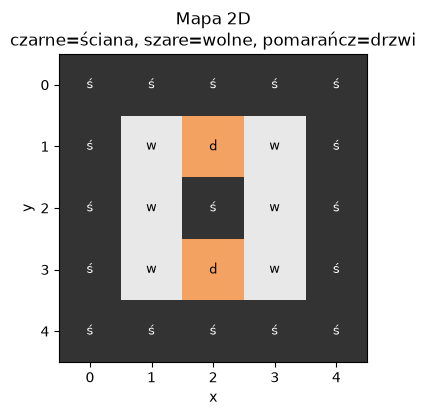

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

SCIANA = 0
WOLNE = 1
DRZWI = 2
nazwy = {SCIANA: "ściana", WOLNE: "wolne", DRZWI: "drzwi"}

# mapa[y, x]
mapa = np.array([
    [SCIANA, SCIANA, SCIANA, SCIANA, SCIANA],
    [SCIANA, WOLNE,  DRZWI,  WOLNE,  SCIANA],
    [SCIANA, WOLNE,  SCIANA, WOLNE,  SCIANA],
    [SCIANA, WOLNE,  DRZWI,  WOLNE,  SCIANA],
    [SCIANA, SCIANA, SCIANA, SCIANA, SCIANA],
], dtype=int)

p_poprawny = 0.8   # sensor trafił
p_bledny = 0.2     # sensor się pomylił

print("mapa (liczby):")
print(mapa)
print()
print("legenda:", nazwy)

cmap = ListedColormap(["#333333", "#e8e8e8", "#f4a261"])
plt.figure(figsize=(4, 4))
plt.imshow(mapa, cmap=cmap, origin="upper")
plt.title("Mapa 2D\nczarne=ściana, szare=wolne, pomarańcz=drzwi")
plt.xlabel("x"); plt.ylabel("y")
for y in range(5):
    for x in range(5):
        plt.text(x, y, nazwy[mapa[y, x]][:1], ha="center", va="center", color="white" if mapa[y,x]==SCIANA else "black", fontsize=9)
plt.xticks(range(5)); plt.yticks(range(5))
plt.show()


### Co robi ten kod?
- Budujemy tablicę `mapa[y, x]` — to nasz świat.
- `0/1/2` to typy komórek (ściana / wolne / drzwi).
- Rysunek pokazuje mapę; robot i cząsteczki mogą stać tylko na **wolne** i **drzwi**.


---
## Krok 1 — Inicjalizacja (rozpisane po kolei)

Cel tego kroku:
1. wypisać pola, po których wolno chodzić,
2. ustawić listę **cząsteczek** (hipotez),
3. ustawić **prawdziwego robota**,
4. policzyć **estymatę** (średnia chmury),
5. policzyć **błąd**,
6. narysować to na mapie.


### 1.a — Które komórki są dozwolone?

Przechodzimy całą mapę `5×5`. Jeśli komórka **nie jest ścianą**, dopisujemy `(x, y)`.


In [2]:
wolne_pola = []
for y in range(5):
    for x in range(5):
        if mapa[y, x] != SCIANA:
            wolne_pola.append((x, y))

print("dozwolone komórki (x, y):", wolne_pola)
print("ile ich jest:", len(wolne_pola))


dozwolone komórki (x, y): [(1, 1), (2, 1), (3, 1), (1, 2), (3, 2), (1, 3), (2, 3), (3, 3)]
ile ich jest: 8


### Co wyszło?
Dozwolone są wszystkie komórki **wolne** i **drzwi** (u nas 8 sztuk).  
Na ścianach cząsteczek nie kładziemy.


### 1.b — Ustawiamy 12 cząsteczek

Każda cząsteczka = jedna hipoteza `(x, y)`.  
Na start rozkładamy je po dozwolonych polach (z powtórkami), żeby nie faworyzować jednego miejsca.


In [3]:
czasteczki = np.array([
    [1, 1], [2, 1], [3, 1],
    [1, 2],         [3, 2],
    [1, 3], [2, 3], [3, 3],
    [1, 1], [2, 1], [3, 3], [1, 3],  # powtórki
], dtype=int)

N = len(czasteczki)
print("N =", N, "cząsteczek")
print()
print("lista cząsteczek:")
for i, (x, y) in enumerate(czasteczki):
    typ = nazwy[mapa[y, x]]
    print(f"  cz.{i:2d}:  (x={x}, y={y})   komórka = {typ}")


N = 12 cząsteczek

lista cząsteczek:
  cz. 0:  (x=1, y=1)   komórka = wolne
  cz. 1:  (x=2, y=1)   komórka = drzwi
  cz. 2:  (x=3, y=1)   komórka = wolne
  cz. 3:  (x=1, y=2)   komórka = wolne
  cz. 4:  (x=3, y=2)   komórka = wolne
  cz. 5:  (x=1, y=3)   komórka = wolne
  cz. 6:  (x=2, y=3)   komórka = drzwi
  cz. 7:  (x=3, y=3)   komórka = wolne
  cz. 8:  (x=1, y=1)   komórka = wolne
  cz. 9:  (x=2, y=1)   komórka = drzwi
  cz.10:  (x=3, y=3)   komórka = wolne
  cz.11:  (x=1, y=3)   komórka = wolne


### Co wyszło?
Mamy tablicę kształtu `(12, 2)` — 12 wierszy, kolumny `x` i `y`.  
To jest nasza **chmura hipotez** na start.


### 1.c — Prawdziwy robot

W symulacji **my** znamy prawdziwą pozycję (żeby potem policzyć błąd).  
Filtr jej **nie dostaje** — dostaje tylko pomiary sensora.


In [4]:
robot = np.array([1, 1])  # start
print("robot = (x, y) =", tuple(robot))
print("typ komórki pod robotem:", nazwy[mapa[robot[1], robot[0]]])


robot = (x, y) = (np.int64(1), np.int64(1))
typ komórki pod robotem: wolne


### Co wyszło?
Robot startuje na `(1, 1)` (wolne). Zielony punkt na mapie = ta pozycja.


### 1.d — Liczymy estymatę (średnia chmury)

Estymata = „gdzie według filtru jest robot” = **średnia** wszystkich cząsteczek.

```text
est_x = (x0 + x1 + … + x11) / N
est_y = (y0 + y1 + … + y11) / N
```


In [5]:
xs = czasteczki[:, 0]   # wszystkie x
ys = czasteczki[:, 1]   # wszystkie y

print("wszystkie x =", xs.tolist())
print("wszystkie y =", ys.tolist())
print()

suma_x = int(xs.sum())
suma_y = int(ys.sum())
print("1.d.i   suma x =", suma_x)
print("1.d.ii  suma y =", suma_y)
print()

est_x = suma_x / N
est_y = suma_y / N
print("1.d.iii est_x = suma_x / N =", suma_x, "/", N, "=", round(est_x, 4))
print("1.d.iv  est_y = suma_y / N =", suma_y, "/", N, "=", round(est_y, 4))
print()
print("estymata = (est_x, est_y) =", (round(est_x, 4), round(est_y, 4)))
print("(to będzie cyan X na mapie)")


wszystkie x = [1, 2, 3, 1, 3, 1, 2, 3, 1, 2, 3, 1]
wszystkie y = [1, 1, 1, 2, 2, 3, 3, 3, 1, 1, 3, 3]

1.d.i   suma x = 23
1.d.ii  suma y = 24

1.d.iii est_x = suma_x / N = 23 / 12 = 1.9167
1.d.iv  est_y = suma_y / N = 24 / 12 = 2.0

estymata = (est_x, est_y) = (1.9167, 2.0)
(to będzie cyan X na mapie)


### Co wyszło?
Dostaliśmy punkt ułamkowy (np. ok. `(2.0, 2.0)`) — średnią chmury.  
Nie musi być na środku komórki; to tylko „środek ciężkości” hipotez.


### 1.e — Liczymy błąd (odległość Manhattan)

Porównujemy estymatę z prawdziwym robotem:

```text
Δx   = |est_x − robot_x|
Δy   = |est_y − robot_y|
błąd = Δx + Δy
```

`błąd = 0` → idealnie; im większy, tym gorzej filtr zgaduje.


In [6]:
robot_x = int(robot[0])
robot_y = int(robot[1])

print("robot_x =", robot_x)
print("robot_y =", robot_y)
print("est_x   =", round(est_x, 4))
print("est_y   =", round(est_y, 4))
print()

dx = abs(est_x - robot_x)
dy = abs(est_y - robot_y)
blad = dx + dy

print("1.e.i   Δx = |est_x − robot_x| = |" + f"{est_x:.4f} − {robot_x}| = {dx:.4f}")
print("1.e.ii  Δy = |est_y − robot_y| = |" + f"{est_y:.4f} − {robot_y}| = {dy:.4f}")
print("1.e.iii błąd = Δx + Δy =", round(dx, 4), "+", round(dy, 4), "=", round(blad, 4))


robot_x = 1
robot_y = 1
est_x   = 1.9167
est_y   = 2.0

1.e.i   Δx = |est_x − robot_x| = |1.9167 − 1| = 0.9167
1.e.ii  Δy = |est_y − robot_y| = |2.0000 − 1| = 1.0000
1.e.iii błąd = Δx + Δy = 0.9167 + 1.0 = 1.9167


### Co wyszło?
To jest liczba, którą potem rysujemy jako **długość fioletowej linii** na mapie  
(robot ↔ estymata). Na starcie zwykle jest dość duża.


### 1.f — Rysujemy mapę z błędem

Pakujemy powyższe liczenie do funkcji `pokaz_mape_z_bledem`  
(użyjemy jej też w kolejnych krokach):

- czerwone punkty = cząsteczki,
- zielony = robot,
- cyan X = estymata,
- fioletowa linia + napis = błąd.


Podsumowanie kroku 1 — to samo, co policzyliśmy ręcznie:

robot     = (1, 1)
estymata  = (1.92, 2.00)
Δx = 0.92   Δy = 1.00   błąd = Δx+Δy = 1.92


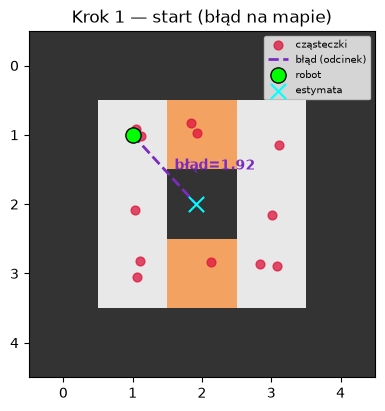

(array([1.91666667, 2.        ]), 1.9166666666666667)

In [7]:
def pokaz_mape_z_bledem(czasteczki, robot, tytul, rng):
    """Liczy estymatę i błąd, rysuje mapę (jak w 1.d–1.e)."""
    parts = np.asarray(czasteczki)
    est = parts.mean(axis=0)
    dx = abs(float(est[0] - robot[0]))
    dy = abs(float(est[1] - robot[1]))
    blad = dx + dy

    print(f"robot     = ({int(robot[0])}, {int(robot[1])})")
    print(f"estymata  = ({est[0]:.2f}, {est[1]:.2f})")
    print(f"Δx = {dx:.2f}   Δy = {dy:.2f}   błąd = Δx+Δy = {blad:.2f}")

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(mapa, cmap=cmap, origin="upper")
    j = (rng.random(parts.shape) - 0.5) * 0.35
    plt.scatter(parts[:, 0] + j[:, 0], parts[:, 1] + j[:, 1],
                s=40, c="crimson", alpha=0.75, label="cząsteczki")
    plt.plot([robot[0], est[0]], [robot[1], est[1]],
             color="#7b2cbf", lw=2, ls="--", zorder=4, label="błąd (odcinek)")
    plt.scatter([robot[0]], [robot[1]], s=120, c="lime", edgecolors="k",
                zorder=5, label="robot")
    plt.scatter([est[0]], [est[1]], s=120, c="cyan", marker="x",
                zorder=6, label="estymata")
    mx, my = (robot[0] + est[0]) / 2, (robot[1] + est[1]) / 2
    plt.text(mx, my, f"  błąd={blad:.2f}", color="#7b2cbf", fontsize=10,
             fontweight="bold", zorder=7)
    plt.title(tytul)
    plt.xticks(range(5)); plt.yticks(range(5))
    plt.legend(loc="upper right", fontsize=7)
    plt.show()
    return est, blad


print("Podsumowanie kroku 1 — to samo, co policzyliśmy ręcznie:\n")
pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 1 — start (błąd na mapie)", np.random.default_rng(0)
)


### Podsumowanie kroku 1

| Co | Jak liczone |
|----|-------------|
| cząsteczki | lista hipotez `(x, y)` |
| robot | prawdziwa pozycja `(1, 1)` |
| `est_x`, `est_y` | suma współrzędnych `/ N` |
| `Δx`, `Δy` | wartość bezwzględna `est − robot` |
| `błąd` | `Δx + Δy` |

Dalej (krok 2): **sense + normalize** — nadamy cząsteczkom wagi z pomiaru.


---
## Krok 2 — Sense + normalize (pierwszy pomiar)

Robot stoi na `(1,1)` → komórka **wolne**.
Załóżmy pomiar: **wolne** (sensor trafił).

Dla każdej cząsteczki:
- jeśli jej komórka też jest **wolne** → waga `0.8`
- w przeciwnym razie → waga `0.2`

Potem **normalizacja**: `w' = w / S`, żeby suma wag = 1.


In [ ]:
# reset stanu (gdyby wcześniej odpalić pętlę / późniejsze komórki)
robot = np.array([1, 1])
czasteczki = np.array([
    [1, 1], [2, 1], [3, 1],
    [1, 2],         [3, 2],
    [1, 3], [2, 3], [3, 3],
    [1, 1], [2, 1], [3, 3], [1, 3],
], dtype=int)
print("robot (nadal start) =", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])
print("(po kroku 3 robot MA zostać na (1,1) — ruchu jeszcze nie było)")
print()

pomiar = WOLNE  # sensor mówi: „wolne”
print("pomiar =", nazwy[pomiar])
print()

w = []
for x, y in czasteczki:
    if mapa[y, x] == pomiar:
        w.append(p_poprawny)
    else:
        w.append(p_bledny)
w = np.array(w)

S = w.sum()
w_prim = np.round(w / S, 3)

print("2.a  S =", round(float(S), 2))
print()
print("2.b")
print("w  (surowe)     =", np.round(w, 3).tolist())
print("w' (po norm.)   =", w_prim.tolist())
print("suma w' =", round(float(w_prim.sum()), 3), "≈ 1")
print()
print("podgląd: typ komórki vs waga")
for i, ((x, y), wi, wp) in enumerate(zip(czasteczki, w, w_prim)):
    print(f"  cz.{i:2d}  ({x},{y})  {nazwy[mapa[y,x]]:7s}  w={wi:.1f}  w'={wp:.3f}")


### Co się dzieje?
- Cząsteczki na **wolnym** dostały wyższą wagę (`0.8`).
- Cząsteczki na **drzwiach** dostały niższą (`0.2`) — bo pomiar mówił „wolne”.
- `S` to suma surowych wag (jak w 1D).
- Po `w/S` mamy rozkład prawdopodobieństwa na hipotezach.


---
## Krok 3 — Resample (ruletka)

Losujemy **nowe 12 cząsteczek** według wag `w'`:
- duża waga → częściej kopiowana,
- mała waga → często znika.

Robimy to CDF + losowe `u` (ta sama ruletka co w zadaniu 1).

**Ważne:** tu jeszcze **nie ma ruchu**. Robot zostaje na `(1,1)`  
(na mapie z `origin="upper"` to górny wolny rząd, nie dolny!).


In [ ]:
# w_prim z kroku 2
cdf = np.cumsum(w_prim)
cdf[-1] = 1.0  # zabezpieczenie zaokrągleń
print("CDF =", np.round(cdf, 3).tolist())

rng = np.random.default_rng(1)
u = rng.random(len(czasteczki))
print("wylosowane u =", np.round(u, 3).tolist())

indeksy = []
for ui in u:
    # pierwsza pozycja w CDF >= u
    idx = int(np.searchsorted(cdf, ui, side="left"))
    idx = min(idx, len(czasteczki) - 1)
    indeksy.append(idx)

nowe = czasteczki[indeksy].copy()
print("wylosowane indeksy starych cząsteczek:", indeksy)
print("nowe cząsteczki (x,y):", nowe.tolist())

from collections import Counter
print("\npowielenie (stary indeks → ile kopii):", dict(Counter(indeksy)))
print()

czasteczki = nowe  # nadpisujemy chmurę
pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 3 — po resamplingiu (błąd na mapie)", rng
)


### Co się dzieje?
Ruletka **powiela** cząsteczki pasujące do pomiaru.
Chmura zaczyna się ściągać — patrz, czy **fioletowa linia (błąd) się skraca**.


---
## Krok 4 — Move (ruch w 2D)

Prosty model (analogia do `+1` w 1D):

```text
próbuj: x ← x + 1   (idź w prawo)
jeśli trafisz w ścianę → zostań w miejscu
```

To samo robimy dla **prawdziwego robota** i dla **każdej cząsteczki**.


In [ ]:
def ruch_w_prawo(x, y):
    """Jeden krok w prawo; ściana blokuje."""
    nx = x + 1
    if 0 <= nx < mapa.shape[1] and mapa[y, nx] != SCIANA:
        return nx, y
    return x, y

print("robot PRZED:", tuple(robot), nazwy[mapa[robot[1], robot[0]]])
robot = np.array(ruch_w_prawo(*robot))
print("robot PO:   ", tuple(robot), nazwy[mapa[robot[1], robot[0]]])

print("\ncząsteczki PRZED:", czasteczki.tolist())
czasteczki = np.array([ruch_w_prawo(x, y) for x, y in czasteczki], dtype=int)
print("cząsteczki PO:   ", czasteczki.tolist())
print()

pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 4 — po ruchu w prawo (błąd na mapie)",
    np.random.default_rng(2),
)


### Co się dzieje?
Wszystkie hipotezy „jadą” tak jak robot.  
Po ruchu znowu liczymy błąd — linia pokazuje, czy estymata nadal trzyma się robota.


---
## Krok 5 — Sense + normalize (pomiar: drzwi)

Po kroku 4 robot jest na `(2,1)` → to **drzwi**.

Robimy **dokładnie to samo** co w kroku 2, tylko pomiar = drzwi:
- waga `0.8` jeśli cząsteczka też stoi na drzwiach,
- waga `0.2` w przeciwnym razie,
- potem `w' = w / S`.


In [ ]:
print("robot jest na", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])

pomiar = DRZWI
print("pomiar =", nazwy[pomiar])
print()

w = []
for x, y in czasteczki:
    if mapa[y, x] == pomiar:
        w.append(p_poprawny)
    else:
        w.append(p_bledny)
w = np.array(w)

S = float(w.sum())
w_prim = np.round(w / S, 3)

print("5.a  S =", round(S, 2))
print()
print("5.b")
print("w  (przed normalizacją) =", np.round(w, 3).tolist())
print("w' (po normalizacji)    =", w_prim.tolist())
print(f"suma w'= {round(float(w_prim.sum()), 3)} ≈ 1")
print()
print("podgląd:")
for i, ((x, y), wi, wp) in enumerate(zip(czasteczki, w, w_prim)):
    print(f"  cz.{i:2d}  ({x},{y})  {nazwy[mapa[y,x]]:7s}  w={wi:.1f}  w'={wp:.3f}")


### Co się dzieje?
Pomiar „drzwi” to **mocny** sygnał — na mapie drzwi jest mało.
Cząsteczki na `D` dostają dużą wagę, reszta małą.
Dalej: ruletka (jak krok 3).


---
## Krok 6 — Resample (ruletka po pomiarze drzwi)

Z `w'` budujemy CDF i losujemy nowe cząsteczki — **jak w kroku 3**.


In [ ]:
cdf = np.cumsum(w_prim)
cdf[-1] = 1.0
print("CDF =", np.round(cdf, 3).tolist())

rng = np.random.default_rng(5)
u = rng.random(len(czasteczki))
print("u   =", np.round(u, 3).tolist())

indeksy = []
for ui in u:
    idx = int(np.searchsorted(cdf, ui, side="left"))
    indeksy.append(min(idx, len(czasteczki) - 1))

czasteczki = czasteczki[indeksy].copy()
print("indeksy starych cząsteczek:", indeksy)
print("nowe cząsteczki (x,y):", czasteczki.tolist())
print()

pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 6 — po resamplingiu (po drzwiach)", rng
)


### Co się dzieje?
Ruletka powiela hipotezy na drzwiach.
Chmura ściąga się koło robota — **błąd na mapie powinien spaść**.
Dalej: ruch — jak krok 4.


---
## Krok 7 — Move w prawo (jeszcze raz)

Znowu ta sama komenda co w kroku 4: `x ← x + 1` (ściana blokuje).

```text
robot: (2,1) drzwi  →  (3,1) wolne
```


In [ ]:
print("robot PRZED:", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])
robot = np.array(ruch_w_prawo(*robot))
print("robot PO:   ", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])

print("\ncząsteczki PRZED:", czasteczki.tolist())
czasteczki = np.array([ruch_w_prawo(x, y) for x, y in czasteczki], dtype=int)
print("cząsteczki PO:   ", czasteczki.tolist())
print()

pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 7 — po ruchu w prawo → (3,1)", np.random.default_rng(2)
)


### Co się dzieje?
Wszyscy pojechali w prawo. Robot jest na `(3,1)` (wolne).

**Uwaga — mapa w prawo się kończy:**
przy `(3,1)` kolejne `x+1` to już **ściana** (`x=4`).
Dlatego **dalej nie jedziemy w prawo** — skręcamy w **dół**.

```text
dotąd:  (1,1) → prawo → (2,1) → prawo → (3,1)
teraz:  (3,1) → dół   → (3,2) → dół   → (3,3)
```

Rytm filtru się **nie zmienia** (sense → normalize → resample → move).
Zmienia się tylko kierunek ruchu: zamiast `ruch_w_prawo` użyjemy `ruch_w_dol`.


---
## Krok 8 — Sense + normalize (trzeci pomiar)

Robot na `(3,1)` → **wolne**.
Znowu jak krok 2 / 5: wagi `0.8/0.2`, potem `/ S`.


In [ ]:
print("robot jest na", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])

pomiar = WOLNE
print("pomiar =", nazwy[pomiar])
print()

w = []
for x, y in czasteczki:
    if mapa[y, x] == pomiar:
        w.append(p_poprawny)
    else:
        w.append(p_bledny)
w = np.array(w)

S = float(w.sum())
w_prim = np.round(w / S, 3)

print("8.a  S =", round(S, 2))
print()
print("8.b")
print("w  (przed normalizacją) =", np.round(w, 3).tolist())
print("w' (po normalizacji)    =", w_prim.tolist())
print(f"suma w'= {round(float(w_prim.sum()), 3)} ≈ 1")
print()
for i, ((x, y), wi, wp) in enumerate(zip(czasteczki, w, w_prim)):
    print(f"  cz.{i:2d}  ({x},{y})  {nazwy[mapa[y,x]]:7s}  w={wi:.1f}  w'={wp:.3f}")


### Co się dzieje?
- Cząsteczki na **wolnym** → waga `0.8`.
- Cząsteczki na **drzwiach** → waga `0.2`.
- `w'` gotowe do ruletki.

Pomiar „wolne” jest **słabszy** niż „drzwi” (więcej pól wolnych → więcej hipotez dostaje dużą wagę).


---
## Krok 9 — Resample

Znowu CDF + losowe `u` — **jak krok 3 i 6**.
Błąd znowu na mapie (ta sama funkcja co od kroku 1).


In [ ]:
cdf = np.cumsum(w_prim)
cdf[-1] = 1.0
print("CDF =", np.round(cdf, 3).tolist())

rng = np.random.default_rng(11)
u = rng.random(len(czasteczki))
print("u   =", np.round(u, 3).tolist())

indeksy = []
for ui in u:
    idx = int(np.searchsorted(cdf, ui, side="left"))
    indeksy.append(min(idx, len(czasteczki) - 1))

czasteczki = czasteczki[indeksy].copy()
print("indeksy:", indeksy)
print("nowe cząsteczki:", czasteczki.tolist())
print()

pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 9 — po resamplingiu", rng
)


### Co się dzieje?
Ruletka + znowu fioletowa linia błędu. Porównaj długość z krokiem 1.


---
## Krok 10 — Move w **dół**

Tu jest jedyna nowość względem kroków 1–7: **kierunek**.

Zamiast `x ← x + 1` robimy:

```text
y ← y + 1     (w dół na mapie)
jeśli ściana → zostań
```

```text
robot: (3,1)  →  (3,2)
```

**Ta sama komenda** idzie do robota i do każdej cząsteczki
(jak `ruch_w_prawo` w kroku 4 i 7).


In [ ]:
def ruch_w_dol(x, y):
    """Jeden krok w dół; ściana blokuje — analogia do ruch_w_prawo."""
    ny = y + 1
    if 0 <= ny < mapa.shape[0] and mapa[ny, x] != SCIANA:
        return x, ny
    return x, y

print("robot PRZED:", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])
robot = np.array(ruch_w_dol(*robot))
print("robot PO:   ", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])

print("\ncząsteczki PRZED:", czasteczki.tolist())
czasteczki = np.array([ruch_w_dol(x, y) for x, y in czasteczki], dtype=int)
print("cząsteczki PO:   ", czasteczki.tolist())
print()

pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 10 — po ruchu w dół → (3,2)\nlinia = błąd", 
    np.random.default_rng(3),
)


### Co się dzieje?
- `y` wzrosło o 1 → wszyscy zjechali o jeden wiersz w dół.
- Robot: `(3,1)` → `(3,2)` (wolne).
- Po ruchu **przeliczamy błąd od nowa** (estymata i robot się przesunęły) — znowu widać fioletową linię.

Dalej znowu: sense → normalize → resample → move w dół.


---
## Krok 11 — Sense + normalize (czwarty pomiar)

Robot na `(3,2)` → znowu **wolne**.
Przepis identyczny jak w krokach 2, 5 i 8.


In [ ]:
print("robot jest na", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])

pomiar = WOLNE
print("pomiar =", nazwy[pomiar])
print()

w = []
for x, y in czasteczki:
    if mapa[y, x] == pomiar:
        w.append(p_poprawny)
    else:
        w.append(p_bledny)
w = np.array(w)

S = float(w.sum())
w_prim = np.round(w / S, 3)

print("11.a  S =", round(S, 2))
print()
print("11.b")
print("w  (przed normalizacją) =", np.round(w, 3).tolist())
print("w' (po normalizacji)    =", w_prim.tolist())
print(f"suma w'= {round(float(w_prim.sum()), 3)} ≈ 1")
print()
for i, ((x, y), wi, wp) in enumerate(zip(czasteczki, w, w_prim)):
    print(f"  cz.{i:2d}  ({x},{y})  {nazwy[mapa[y,x]]:7s}  w={wi:.1f}  w'={wp:.3f}")


### Co się dzieje?
Znowu wagi z pomiaru „wolne” + normalizacja.
Im więcej razy to powtórzymy w czasie (i im bardziej unikalne pomiary),
tym lepiej chmura trzyma się prawdziwej trasy.


---
## Krok 12 — Resample

Ruletka — jak kroki 3, 6 i 9.


In [ ]:
cdf = np.cumsum(w_prim)
cdf[-1] = 1.0
print("CDF =", np.round(cdf, 3).tolist())

rng = np.random.default_rng(13)
u = rng.random(len(czasteczki))
print("u   =", np.round(u, 3).tolist())

indeksy = []
for ui in u:
    idx = int(np.searchsorted(cdf, ui, side="left"))
    indeksy.append(min(idx, len(czasteczki) - 1))

czasteczki = czasteczki[indeksy].copy()
print("indeksy:", indeksy)
print("nowe cząsteczki:", czasteczki.tolist())
print()

pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 12 — po resamplingiu\nlinia = błąd", rng
)


### Co się dzieje?
Chmura powinna być bliżej zielonego niż na starcie.
Patrz na **długość fioletowej linii** — krótsza = mniejszy błąd.


---
## Krok 13 — Move w dół (jeszcze raz)

Drugi ruch w dół — znowu `ruch_w_dol`, jak krok 10.

```text
robot: (3,2)  →  (3,3)  wolne
```


In [ ]:
print("robot PRZED:", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])
robot = np.array(ruch_w_dol(*robot))
print("robot PO:   ", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])

print("\ncząsteczki PRZED:", czasteczki.tolist())
czasteczki = np.array([ruch_w_dol(x, y) for x, y in czasteczki], dtype=int)
print("cząsteczki PO:   ", czasteczki.tolist())
print()

pokaz_mape_z_bledem(
    czasteczki, robot, "Krok 13 — po ruchu w dół → (3,3)\nlinia = błąd",
    np.random.default_rng(4),
)


### Co się dzieje?
Wszyscy zjechali jeszcze raz. Robot na `(3,3)`.

Cała ręczna trasa wyglądała tak:

```text
(1,1) --prawo--> (2,1) --prawo--> (3,1) --dół--> (3,2) --dół--> (3,3)
         ↑ drzwi              ↑ tu skręt w dół
```

A filtr w każdym miejscu robił to samo:

```text
sense → normalize → resample → move
```

Poniżej tylko pakujemy to w pętlę, żeby nie kopiować komórek 20 razy.


---
## Krok 14 — Na koniec: to samo w pętli

Dotąd robiliśmy **ręcznie** kroki 2–13.
Teraz te same operacje w funkcjach i w `for` — bez przepisywania.

W **jednym** obrocie pętli zawsze jest ta sama kolejność:

```text
1. SENSE + NORMALIZE   →  wagi z pomiaru
2. ESTYMATA            →  „gdzie według filtru jestem?” (średnia chmury)
3. RESAMPLE            →  ruletka powiela dobre hipotezy
4. MOVE                →  robot i cząsteczki robią TEN SAM ruch
```

Na rysunku:
- **czerwone** = cząsteczki (hipotezy),
- **zielone** = prawdziwy robot,
- **cyan X** = estymata (średnia chmury).


### 14.a — Funkcje pomocnicze (to, co już znasz, tylko spakowane)

| Funkcja | Odpowiednik z kroków 2–4 |
|---------|--------------------------|
| `sense_normalize` | wagi `0.8/0.2` + dzielenie przez `S` |
| `resample` | CDF + losowe `u` (ruletka) |
| `idz(x, y, dx, dy)` | ruch o wektor — prawo `(1,0)`, dół `(0,1)`, … |
| `estymata` | średnia `(x, y)` po wszystkich cząsteczkach |
| `narysuj` | mapa + chmura + robot + X |

`idz` zamiast samego `ruch_w_prawo`: jeden kod obsługuje **wszystkie kierunki**.


In [ ]:
def sense_normalize(czasteczki, pomiar):
    """Sense + normalize — jak krok 2."""
    w = np.array([
        p_poprawny if mapa[y, x] == pomiar else p_bledny
        for x, y in czasteczki
    ], dtype=float)
    S = float(w.sum())
    w_prim = w / S          # suma w' = 1
    return w, S, w_prim


def resample(czasteczki, w_prim, rng):
    """Ruletka CDF — jak krok 3."""
    cdf = np.cumsum(w_prim)
    cdf[-1] = 1.0
    u = rng.random(len(czasteczki))
    idx = np.searchsorted(cdf, u, side="left")
    idx = np.clip(idx, 0, len(czasteczki) - 1)
    return czasteczki[idx].copy()


def idz(x, y, dx, dy):
    """Ruch o (dx, dy). Ściana albo brzeg mapy → zostań."""
    nx, ny = x + dx, y + dy
    if 0 <= nx < 5 and 0 <= ny < 5 and mapa[ny, nx] != SCIANA:
        return nx, ny
    return x, y


def estymata(czasteczki):
    """Średnia pozycji chmury = odpowiedź filtru."""
    return czasteczki.mean(axis=0)   # np. (2.3, 1.1)


def narysuj(czasteczki, robot, tytul, rng):
    """Jak pokaz_mape_z_bledem — z linią błędu."""
    est = estymata(czasteczki)
    dx = abs(est[0] - robot[0])
    dy = abs(est[1] - robot[1])
    blad = dx + dy

    plt.figure(figsize=(3.8, 3.8))
    plt.imshow(mapa, cmap=cmap, origin="upper")
    j = (rng.random(czasteczki.shape) - 0.5) * 0.35
    plt.scatter(czasteczki[:, 0] + j[:, 0], czasteczki[:, 1] + j[:, 1],
                s=35, c="crimson", alpha=0.75, label="cząsteczki")
    plt.plot([robot[0], est[0]], [robot[1], est[1]],
             color="#7b2cbf", lw=2, ls="--", zorder=4, label=f"błąd={blad:.2f}")
    plt.scatter([robot[0]], [robot[1]], s=110, c="lime", edgecolors="k",
                zorder=5, label="robot")
    plt.scatter([est[0]], [est[1]], s=90, c="cyan", marker="x", zorder=6, label="estymata")
    mx, my = (robot[0] + est[0]) / 2, (robot[1] + est[1]) / 2
    plt.text(mx, my, f"  {blad:.2f}", color="#7b2cbf", fontsize=9, fontweight="bold", zorder=7)
    plt.title(tytul)
    plt.xticks(range(5)); plt.yticks(range(5))
    plt.legend(loc="upper right", fontsize=7)
    plt.show()
    return blad

print("Funkcje gotowe: sense_normalize, resample, idz, estymata, narysuj")


### Co robią te funkcje (krótko)?

1. **`sense_normalize`** — dla każdej hipotezy: pasuje do pomiaru? → `0.8` albo `0.2`, potem `/ S`.
2. **`resample`** — buduje CDF, losuje `u`, bierze indeksy → nowa lista cząsteczek (z kopiami).
3. **`idz`** — `dx, dy` to kierunek:
   - prawo `(1, 0)`, lewo `(-1, 0)`, dół `(0, 1)`, góra `(0, -1)`.
4. **`estymata`** — średnia wszystkich `(x,y)`; cyan X na mapie.
5. **`narysuj`** — tylko wizualizacja (filtr bez tego też działa).


### 14.b — Trasa robota

Żeby dało się **śledzić ręcznie**, nie losujemy ruchu.
Ustalamy listę komend `(dx, dy)`:

```text
start (1,1)
  → prawo (1,0)  →  (2,1)  drzwi
  → prawo (1,0)  →  (3,1)  wolne
  → dół   (0,1)  →  (3,2)  wolne
  → dół   (0,1)  →  (3,3)  wolne
  → lewo (-1,0)  →  (2,3)  drzwi
  → lewo (-1,0)  →  (1,3)  wolne
```

**Ważne:** w każdym kroku pętli **ta sama** komenda `(dx, dy)` idzie do robota **i** do każdej cząsteczki.
(Filtr zakłada: „jeśli robot dostał komendę jedź w prawo, hipotezy też powinny”.)


In [ ]:
# kierunki: (dx, dy)
#  prawo=(1,0)   lewo=(-1,0)   dół=(0,1)   góra=(0,-1)
trasa = [
    (1, 0),   # 1. prawo
    (1, 0),   # 2. prawo
    (0, 1),   # 3. dół
    (0, 1),   # 4. dół
    (-1, 0),  # 5. lewo
    (-1, 0),  # 6. lewo
]

print("trasa (kolejne komendy ruchu):")
nazwy_kier = {(1, 0): "prawo", (-1, 0): "lewo", (0, 1): "dół", (0, -1): "góra"}
for i, (dx, dy) in enumerate(trasa, start=1):
    print(f"  krok {i}: {nazwy_kier[(dx, dy)]:5s}  (dx={dx}, dy={dy})")


### 14.c — Start od zera + pętla

Resetujemy robota i cząsteczki (jak w kroku 1), potem dla każdej komendy z trasy:

```text
pomiar  = typ komórki pod PRAWDZIWYM robotem     # sense
w, S, w' = sense_normalize(...)
est     = średnia chmury                         # estymata
błąd    = |est_x - robot_x| + |est_y - robot_y|  # jak daleko jesteśmy
cząsteczki = resample(...)                       # ruletka
robot, cząsteczki = idz(... ta sama komenda ...) # move
```

Błąd liczymy **przed** ruchem (po sense) — wtedy widać, czy sam pomiar już poprawia lokalizację.


In [ ]:
rng = np.random.default_rng(7)

# --- start jak w kroku 1 ---
robot = np.array([1, 1])
czasteczki = np.array([
    [1, 1], [2, 1], [3, 1], [1, 2], [3, 2], [1, 3],
    [2, 3], [3, 3], [1, 1], [2, 1], [3, 3], [1, 3],
], dtype=int)

print("START  robot =", tuple(robot), "→", nazwy[mapa[robot[1], robot[0]]])
print("START  cząsteczki =", czasteczki.tolist())
narysuj(czasteczki, robot, "START — rozproszone hipotezy", rng)

bledy = []

for t, (dx, dy) in enumerate(trasa, start=1):
    # ----- 1) SENSE + NORMALIZE -----
    pomiar = mapa[robot[1], robot[0]]   # co „widzi” robot tu, gdzie stoi
    w, S, w_prim = sense_normalize(czasteczki, pomiar)

    # ----- 2) ESTYMATA + BŁĄD -----
    est = estymata(czasteczki)
    blad = abs(est[0] - robot[0]) + abs(est[1] - robot[1])
    bledy.append(blad)

    # ----- 3) RESAMPLE -----
    czasteczki = resample(czasteczki, w_prim, rng)

    # ----- 4) MOVE (ta sama komenda dla wszystkich) -----
    kierunek = nazwy_kier[(dx, dy)]
    robot = np.array(idz(robot[0], robot[1], dx, dy))
    czasteczki = np.array([idz(x, y, dx, dy) for x, y in czasteczki], dtype=int)

    print(f"\n=== krok {t} ===")
    print(f"  pomiar = {nazwy[pomiar]}   S = {S:.2f}")
    print(f"  estymata ≈ ({est[0]:.2f}, {est[1]:.2f})   błąd ≈ {blad:.2f}")
    print(f"  ruch: {kierunek}  →  robot teraz {tuple(robot)}")
    print(f"  cząsteczki po cyklu: {czasteczki.tolist()}")
    narysuj(czasteczki, robot, f"po kroku {t} (ruch: {kierunek})", rng)

print("\nBłędy po kolejnych krokach:", [round(b, 2) for b in bledy])


### Co wypisuje pętla?
- **`pomiar`** — typ komórki pod robotem w tej chwili (sense).
- **`S`** — suma surowych wag (jak w 1D); większe S ≈ więcej hipotez „pasowało”.
- **`estymata`** — średnia chmury **przed** resamplingiem/ruchem.
- **`błąd`** — odległość Manhattan `|Δx|+|Δy|` między estymatą a robotem (0 = idealnie).
- **`ruch`** — która komenda poszła do `idz`.

Na mapach patrz, czy **czerwona chmura** zbliża się do **zielonego** punktu, a **cyan X** też.


### 14.d — Wykres błędu w czasie

Jeśli filtr działa, błąd **spada** (z małymi wahaniami).
Skok w górę może się zdarzyć przy niejednoznacznym pomiarze (same „wolne”) albo pechowej ruletce.


In [ ]:
plt.figure(figsize=(7, 3.2))
plt.plot(range(1, len(bledy) + 1), bledy, "o-", color="#1d3557", lw=2)
plt.xlabel("numer kroku pętli")
plt.ylabel("błąd = |Δx| + |Δy|")
plt.title("Zbieżność lokalizacji — im niżej, tym lepiej filtr „wie gdzie jest”")
plt.xticks(range(1, len(bledy) + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"błąd na początku ≈ {bledy[0]:.2f}")
print(f"błąd na końcu    ≈ {bledy[-1]:.2f}")
print("udało się poprawić lokalizację?", bledy[-1] < bledy[0])


### Jak czytać ten wykres?
- **Spadek** → po sense/resample chmura jest bliżej prawdy.
- **Płasko / skok** → pomiar mało informacyjny (np. znowu „wolne”) albo pechowy resample.
- Przejazd przez **drzwi** zwykle pomaga najbardziej (unikalny pomiar na mapie).


---
## Podsumowanie kodu (wymagane w zadaniu)

| Fragment w kodzie | Rola w filtrze |
|-------------------|----------------|
| `mapa[y, x]` | świat 2D (ściana / wolne / drzwi) |
| `czasteczki` | hipotezy pozycji `(x, y)` |
| `sense_normalize` | **sense + normalize** — wagi z pomiaru, `/ S` |
| `resample` + CDF | **resample** — ruletka, powielanie dobrych |
| `idz(dx, dy)` | **move** — ta sama komenda dla robota i chmury |
| `estymata` = `mean` | odpowiedź: „tu według mnie jesteś” |
| pętla `for` po `trasa` | powtarzanie cyklu w czasie |

### Jedno zdanie na obronę
Trzymamy chmurę zgadywanek na kratce; pomiar podbija pasujące; ruletka je powiela;
ruch przesuwa wszystkich tą samą komendą — i tak lokalizujemy robota w 2D.

### Co dalej?
- Ten notebook = zadanie 2 (implementacja + wyjaśnienie).
- Zadanie 3 = demo animacji (`zadanie_3_demo/`) na bogatszym wariancie.
